In [1]:
import pandas as pd
import os
from skimage.transform import resize
from skimage.io import imread
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

In [4]:
Categories =['Audi','Mahindra Scorpio']
flat_data_arr =[]
target_arr = []
datadir = r'C:\Users\anshu\OneDrive\Desktop\dd'
for i in Categories:

    print(f'loading...category : {i}')
    path= os.path.join(datadir,i)
    for img in os.listdir(path):
        img_array = imread(os.path.join(path,img))
        img_resized = resize(img_array,(150,150,3))
        flat_data_arr.append(img_resized.flatten())
        target_arr.append(Categories.index(i))
    print(f'loaded category: {i} succesfully')

flat_data = np.array(flat_data_arr)
target = np.array(target_arr)

loading...category : Audi
loaded category: Audi succesfully
loading...category : Mahindra Scorpio
loaded category: Mahindra Scorpio succesfully


In [5]:
df = pd.DataFrame(flat_data)
df['Target']=target
df.shape

(100, 67501)

In [6]:
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [7]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.20,random_state =77,stratify = y)

In [8]:
param_grid = {'C':[0.1,1,10,100],
              'gamma':[0.0001,0.001,0.1,1],
              'kernel':['rbf','poly']
             }

svc = svm.SVC(probability = True)

model = GridSearchCV(svc,param_grid)

In [9]:
model.fit(x_train,y_train)

GridSearchCV(estimator=SVC(probability=True),
             param_grid={'C': [0.1, 1, 10, 100],
                         'gamma': [0.0001, 0.001, 0.1, 1],
                         'kernel': ['rbf', 'poly']})

In [12]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_pred,y_test)

print(f"The model is {accuracy *100} % accurate")

The model is 55.00000000000001 % accurate


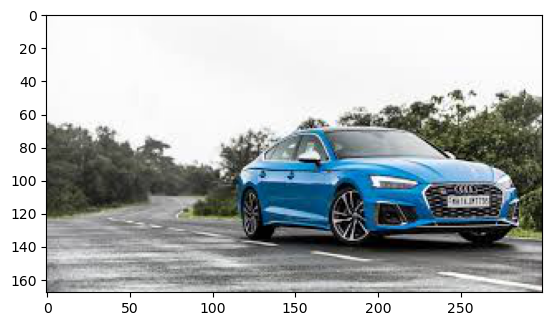

Audi = 98.7895981841892%
Mahindra Scorpio = 1.2104018158107896%
the predicted is :Audi


In [14]:
path = r"C:\Users\anshu\OneDrive\Desktop\dd\Audi\938.jpg"
img = imread(path)
plt.imshow(img)
plt.show()
img_resize = resize(img,(150,150,3))
p =[img_resize.flatten()]
probability = model.predict_proba(p)
for ind,val in enumerate(Categories):
    print(f'{val} = {probability[0][ind]*100}%')
print("the predicted is :"+Categories[model.predict(p)[0]])

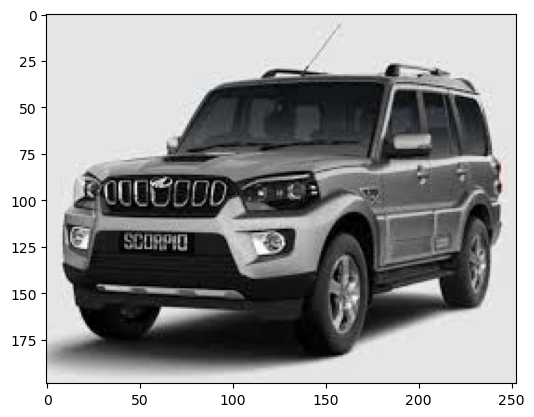

Audi = 1.2180465803228961%
Mahindra Scorpio = 98.7819534196771%
the predicted is :Mahindra Scorpio


In [16]:
path = r"C:\Users\anshu\OneDrive\Desktop\dd\Mahindra Scorpio\186.jpg"
img = imread(path)
plt.imshow(img)
plt.show()
img_resize = resize(img,(150,150,3))
p =[img_resize.flatten()]
probability = model.predict_proba(p)
for ind,val in enumerate(Categories):
    print(f'{val} = {probability[0][ind]*100}%')
print("the predicted is :"+Categories[model.predict(p)[0]])